# **ЛАБОРАТОРНА РОБОТА 7**
## **Prac 07.1**

In [27]:
import os
import cv2
from matplotlib import pyplot as plt
import numpy as np

from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Dense, Input

plt.rcParams['figure.figsize'] = [15, 6]

np.random.seed(42)
tf.random.set_seed(42)

## **1. Завантаження та підготовка даних**

In [28]:
folder = "data/subset_homework"

images_0 = []
images_1 = []

In [29]:
for filename in os.listdir(os.path.join(folder, "class_id_0")):
    
    path = os.path.join(folder, "class_id_0", filename)
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (32, 32))
    images_0.append(img)

for filename in os.listdir(os.path.join(folder, "class_id_1")):
    
    path = os.path.join(folder, "class_id_1", filename)
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (32, 32))
    images_1.append(img)
    
labels_0 = [0] * len(images_0)
labels_1 = [1] * len(images_1)

print("Кількість зображень у class_id_0:", len(images_0))
print("Кількість зображень у class_id_1:", len(images_1))
print("Загальна кількість:", len(images_0) + len(images_1))

Кількість зображень у class_id_0: 2220
Кількість зображень у class_id_1: 2250
Загальна кількість: 4470


### Візуалізація класів

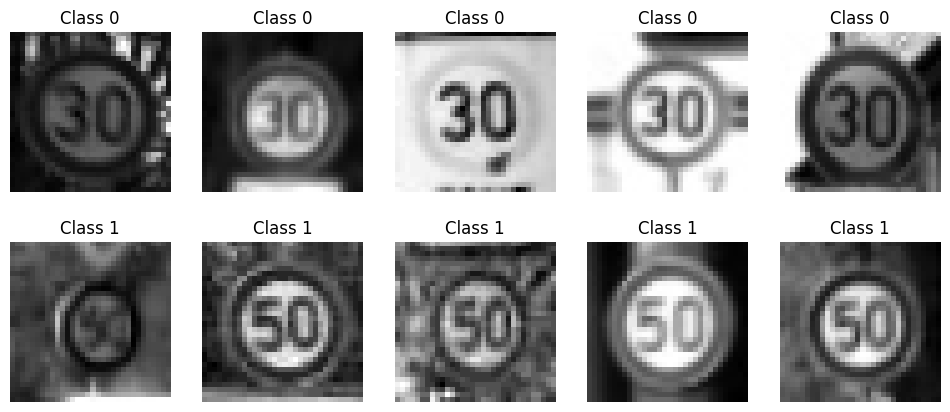

In [30]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, idx in enumerate(np.random.choice(len(images_0), min(5, len(images_0)), replace=False)):
    axes[0, i].imshow(images_0[idx], cmap="gray")
    axes[0, i].set_title("Class 0")
    axes[0, i].axis("off")

for i, idx in enumerate(np.random.choice(len(images_1), min(5, len(images_1)), replace=False)):
    axes[1, i].imshow(images_1[idx], cmap="gray")
    axes[1, i].set_title("Class 1")
    axes[1, i].axis("off")

plt.show()

### Об'єднання двох класів

In [31]:
images = images_0 + images_1
labels = labels_0 + labels_1

images, labels = shuffle(images, labels, random_state=42)

images = np.array(images)
labels = np.array(labels)

print("Images:", images.shape)
print("Labels:", labels.shape)

Images: (4470, 32, 32)
Labels: (4470,)


### Нормалізація пікселів

In [32]:
pixels = np.array([image.flatten() for image in images]) / 255.0

print("Pixels shape:", pixels.shape)

Pixels shape: (4470, 1024)


### Розділення на тестову та навчальну частини

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    pixels,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3576, 1024)
X_test: (894, 1024)
y_train: (3576,)
y_test: (894,)


## **2. Створення одношарової нейронної мережі з одним нейроном**

In [34]:
inputs = Input(shape=(X_train.shape[1],))
outputs = Dense(1, activation="sigmoid")(inputs)
model_1 = Model(inputs, outputs)

model_1.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

### Навчання

In [35]:
model_1.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history_1 = model_1.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.5900 - loss: 0.6751 - val_accuracy: 0.6432 - val_loss: 0.6360
Epoch 2/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6748 - loss: 0.6236 - val_accuracy: 0.7114 - val_loss: 0.5957
Epoch 3/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7184 - loss: 0.5889 - val_accuracy: 0.7461 - val_loss: 0.5643
Epoch 4/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7497 - loss: 0.5602 - val_accuracy: 0.7729 - val_loss: 0.5379
Epoch 5/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7819 - loss: 0.5356 - val_accuracy: 0.8009 - val_loss: 0.5151
Epoch 6/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8043 - loss: 0.5141 - val_accuracy: 0.8166 - val_loss: 0.4950
Epoch 7/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8261 - loss: 0.4949 - val_accuracy: 0.8311 - val_loss: 0.4771
Epoch 8/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8414 - loss: 0.4777 - val_accuracy: 0.

In [36]:
loss, accuracy = model_1.evaluate(X_test, y_test, verbose=0)

print(f"Test loss: {loss:.4f}")
print(f"Test accuracy: {accuracy * 100:.2f}%")

Test loss: 0.3420
Test accuracy: 91.16%


### Графіки точності моделі та функції втрат

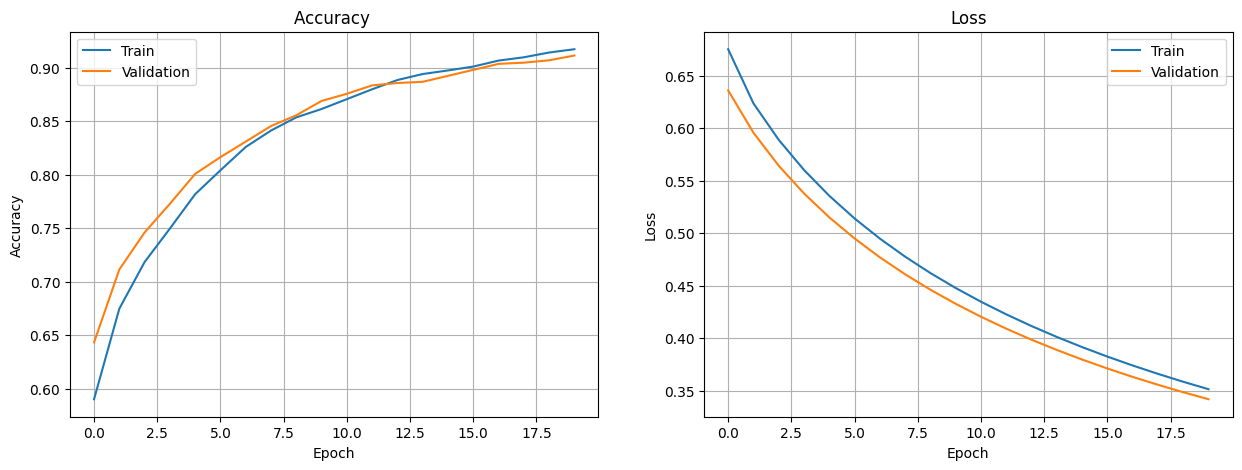

In [37]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(history_1.history["accuracy"], label="Train")
plt.plot(history_1.history["val_accuracy"], label="Validation")
plt.title("Accuracy ")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_1.history["loss"], label="Train")
plt.plot(history_1.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

## **3. Покращення моделі**
Для підвищення точності створено нейронну мережу з двома прихованими шарами, що містять 64 та 32 нейрони з функцією активації ReLU. 

In [38]:
inputs = Input(shape=(X_train.shape[1],))

x = Dense(64, activation="relu")(inputs)
x = Dense(32, activation="relu")(x)

outputs = Dense(1, activation="sigmoid")(x)

model_2 = Model(inputs, outputs)

model_2.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,713 (264.50 KB)

 Trainable params: 67,713 (264.50 KB)

 Non-trainable params: 0 (0.00 B)

### Навчання

In [39]:
model_2.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history_2 = model_2.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6518 - loss: 0.6287 - val_accuracy: 0.7148 - val_loss: 0.5629
Epoch 2/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7707 - loss: 0.5086 - val_accuracy: 0.8210 - val_loss: 0.4461
Epoch 3/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8400 - loss: 0.4097 - val_accuracy: 0.8345 - val_loss: 0.3982
Epoch 4/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8770 - loss: 0.3433 - val_accuracy: 0.8546 - val_loss: 0.3494
Epoch 5/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8974 - loss: 0.2969 - val_accuracy: 0.8837 - val_loss: 0.3033
Epoch 6/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9130 - loss: 0.2611 - val_accuracy: 0.9027 - val_loss: 0.2546
Epoch 7/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9256 - loss: 0.2330 - val_accuracy: 0.9083 - val_loss: 0.2332
Epoch 8/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9309 - loss: 0.2118 - val_accuracy: 0.

In [40]:
loss, accuracy = model_2.evaluate(X_test, y_test, verbose=0)

print(f"Test loss: {loss:.4f}")
print(f"Test accuracy: {accuracy * 100:.2f}%")

Test loss: 0.1102
Test accuracy: 95.75%


### Графік точності моделі

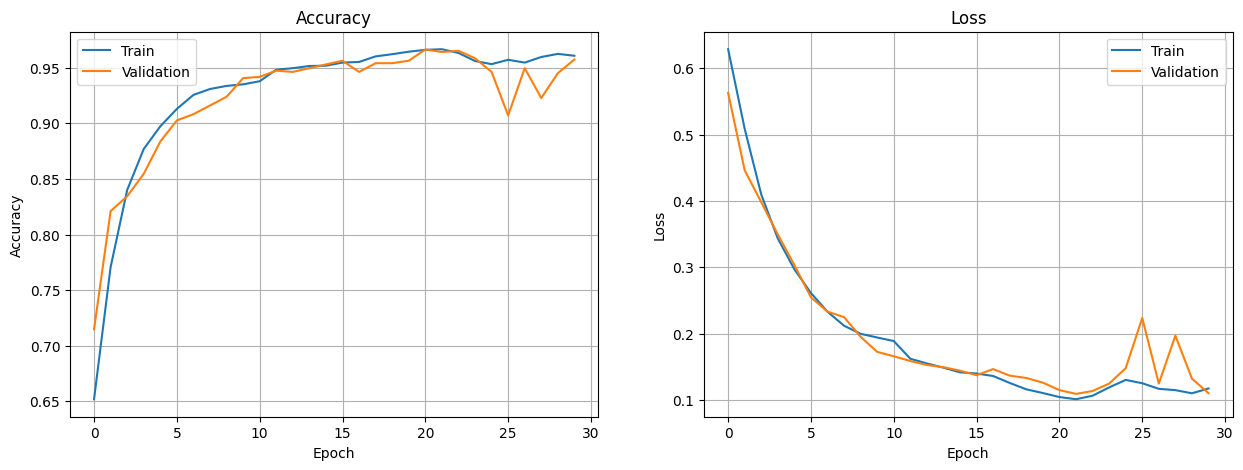

In [41]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(history_2.history["accuracy"], label="Train")
plt.plot(history_2.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_2.history["loss"], label="Train")
plt.plot(history_2.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()